In [ ]:
from pathlib import Path
import json
import pickle
import random
import re
from typing import Any, Dict, List, Optional, Tuple


import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from IPython.display import clear_output
from torch.utils.data import DataLoader, Dataset, Subset
from torch_geometric.data import Batch

from gnn_rl_core import GATStateEncoder, GNNSurrogateEnv, convert_to_pyg_data
plt.style.use("seaborn-v0_8-whitegrid")
np.random.seed(42)
random.seed(42)
torch.manual_seed(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)
print("torch version:", torch.__version__)

device: cuda
torch version: 2.11.0+cu130


In [ ]:
DATA_ROOT = Path("./data/trajectories")
CHECKPOINT_DIR = Path("./checkpoints/graph_gnn")
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

EXPERT_ONLY = True
TREE_LEVEL_SPLIT = True
VAL_RATIO = 0.15
SPLIT_SEED = 42
BATCH_SIZE = 32
NUM_EPOCHS = 120
LR = 3e-4
WEIGHT_DECAY = 1e-4
STATE_DIM = 128
SURROGATE_LOSS_WEIGHT = 0.25
PLOT_EVERY = 5
EARLY_STOPPING_PATIENCE = 15
MIN_EPOCHS_BEFORE_STOP = 20


def _load_serialized_trajectory(file_path: Path) -> Dict[str, Any]:
    suffix = file_path.suffix.lower()
    if suffix == ".npz":
        with np.load(file_path, allow_pickle=True) as data:
            return {k: data[k] for k in data.files}
    if suffix == ".pt":
        return torch.load(file_path, map_location="cpu")
    if suffix in {".pkl", ".pickle"}:
        with open(file_path, "rb") as f:
            return pickle.load(f)
    if suffix == ".json":
        with open(file_path, "r", encoding="utf-8") as f:
            return json.load(f)
    raise ValueError(f"Unsupported trajectory file type: {file_path}")


def _as_numpy_list(x: Any) -> List[np.ndarray]:
    if x is None:
        return []
    if isinstance(x, list):
        return [np.asarray(item) for item in x]
    if isinstance(x, tuple):

        return [np.asarray(item) for item in x]
    if isinstance(x, np.ndarray):
        if x.dtype == object:
            return [np.asarray(item) for item in x.tolist()]
        if x.ndim == 3:
            return [np.asarray(x[i]) for i in range(x.shape[0])]
        return [np.asarray(x)]
    if torch.is_tensor(x):
        x = x.detach().cpu().numpy()
        if x.ndim == 3:
            return [np.asarray(x[i]) for i in range(x.shape[0])]
        return [np.asarray(x)]
    return [np.asarray(x)]



def _find_trajectory_files(root: Path) -> List[Path]:
    files = [
        p for p in root.rglob("*")
        if p.is_file()
        and p.suffix.lower() in {".npz", ".pt", ".pkl", ".pickle", ".json"}
        and any(key in p.name.lower() for key in ("trajectory", "episode", "traj"))
    ]
    return sorted(files)


def _extract_tree_key(file_path: Path) -> str:
    match = re.search(r"(Lemon\d+_\d+)", file_path.stem)
    return match.group(1) if match else file_path.stem


def _infer_root_branch_id(skeleton_step: np.ndarray) -> Optional[int]:
    sk = np.asarray(skeleton_step, dtype=np.float32).reshape(-1, 6)
    if sk.size == 0:
        return None
    parent_idx = np.round(sk[:, 4]).astype(int)
    branch_ids = np.round(sk[:, 5]).astype(int)
    root_mask = parent_idx <= 0
    if root_mask.any():
        vals, counts = np.unique(branch_ids[root_mask], return_counts=True)
        return int(vals[np.argmax(counts)])
    valid = [int(b) for b in np.unique(branch_ids) if int(b) >= 0]
    return int(valid[0]) if valid else None



def _build_valid_raw_actions(skeleton_step: np.ndarray, stop_action: int = -1) -> List[int]:
    sk = np.asarray(skeleton_step, dtype=np.float32).reshape(-1, 6)
    if sk.size == 0:
        return [stop_action]
    branch_ids = np.round(sk[:, 5]).astype(int)
    root_branch = _infer_root_branch_id(sk)
    valid = [int(b) for b in np.unique(branch_ids) if int(b) >= 0 and int(b) != root_branch]
    valid = sorted(valid)
    valid.append(int(stop_action))
    return valid



def _tree_stats(point_cloud: np.ndarray, skeleton_step: np.ndarray) -> Dict[str, float]:
    pc = np.asarray(point_cloud, dtype=np.float32).reshape(-1, 3)
    sk = np.asarray(skeleton_step, dtype=np.float32).reshape(-1, 6)
    xyz_parts = []
    if pc.size:
        xyz_parts.append(pc[:, :3])
    if sk.size:
        xyz_parts.append(sk[:, :3])
    if not xyz_parts:
        return {
            "height": 0.0,
            "coverage": 0.0,
            "branch_count": 0.0,
            "skeleton_length": 0.0,
            "point_count": 0.0,
        }

    xyz = np.concatenate(xyz_parts, axis=0)
    bbox_span = np.maximum(xyz.max(axis=0) - xyz.min(axis=0), 1e-6)
    height = float(bbox_span[2])
    coverage = float(np.linalg.norm(bbox_span[:2]))

    if sk.size:
        branch_ids = np.round(sk[:, 5]).astype(int)
        branch_count = float(len([b for b in np.unique(branch_ids) if int(b) >= 0]))
        parent_raw = np.round(sk[:, 4]).astype(int)
        skel_length = 0.0
        for child_idx, parent in enumerate(parent_raw):
            parent_candidates = [parent - 1, parent]
            for parent_idx in parent_candidates:
                if 0 <= parent_idx < len(sk) and parent_idx != child_idx:
                    skel_length += float(np.linalg.norm(sk[child_idx, :3] - sk[parent_idx, :3]))
                    break
    else:
        branch_count = 0.0
        skel_length = 0.0

    return {
        "height": height,
        "coverage": coverage,
        "branch_count": branch_count,
        "skeleton_length": float(skel_length),
        "point_count": float(len(pc)),
    }


def compute_proxy_kpi_delta(
    current_pc: np.ndarray,
    current_sk: np.ndarray,
    next_pc: np.ndarray,
    next_sk: np.ndarray,
    reward_value: float,
) -> np.ndarray:
    prev_stats = _tree_stats(current_pc, current_sk)
    next_stats = _tree_stats(next_pc, next_sk)

    delta = np.array([
        (next_stats["height"] - prev_stats["height"]) / max(prev_stats["height"], 1e-6),
        (next_stats["coverage"] - prev_stats["coverage"]) / max(prev_stats["coverage"], 1e-6),
        (next_stats["branch_count"] - prev_stats["branch_count"]) / max(prev_stats["branch_count"], 1.0),
        (next_stats["skeleton_length"] - prev_stats["skeleton_length"]) / max(prev_stats["skeleton_length"], 1e-6),
        (prev_stats["point_count"] - next_stats["point_count"]) / max(prev_stats["point_count"], 1.0),
        float(np.tanh(reward_value / 3.0)),
    ], dtype=np.float32)
    return np.nan_to_num(delta, nan=0.0, posinf=0.0, neginf=0.0)

trajectory_files = _find_trajectory_files(DATA_ROOT)
if EXPERT_ONLY:
    trajectory_files = [p for p in trajectory_files if p.name.startswith("expert_traj_")]

print("trajectory root:", DATA_ROOT)
print("trajectory files:", len(trajectory_files))
print("example:", trajectory_files[0] if trajectory_files else "None")


trajectory root: data/trajectories
trajectory files: 43
example: data/trajectories/expert_traj_Lemon00_01.pkl


===== Graph Dataset Ready =====
expert trajectories: 43
step samples: 7663
train samples: 6557
val samples: 1106
unique trees: 43
action_dim: 805
STOP mapping: -1 -> 0

Sample graph
nodes: 6225 edges: 6224 points: 56742
raw action: 626 mapped idx: 613
proxy kpi delta: [ 0.          0.         -0.00158479 -0.00118195  0.00091643  0.08183406]


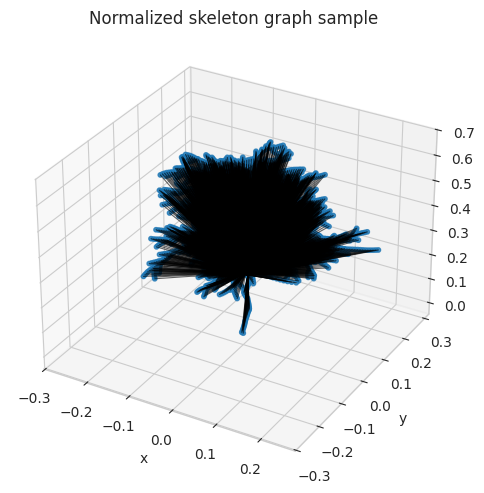

In [ ]:
class GraphLemonTreeDataset(Dataset):
    def __init__(self, data_root: Path, expert_only: bool = True) -> None:
        self.data_root = Path(data_root)
        self.expert_only = bool(expert_only)
        self.trajectory_files = _find_trajectory_files(self.data_root)
        if self.expert_only:
            self.trajectory_files = [p for p in self.trajectory_files if p.name.startswith("expert_traj_")]
        if not self.trajectory_files:
            raise FileNotFoundError(f"在 {self.data_root} 下没有找到可用轨迹。")

        self.traj_cache: Dict[str, Dict[str, Any]] = {}
        self.samples: List[Tuple[Path, int]] = []
        self.sample_tree_keys: List[str] = []
        unique_actions = set()
        for file_path in self.trajectory_files:
            traj = _load_serialized_trajectory(file_path)
            self.traj_cache[str(file_path)] = traj
            point_clouds = _as_numpy_list(traj.get("point_clouds"))
            skeletons = _as_numpy_list(traj.get("skeletons"))
            actions = np.asarray(traj.get("actions", []), dtype=np.int64).reshape(-1)
            rewards = np.asarray(traj.get("rewards", []), dtype=np.float32).reshape(-1)
            returns_to_go = np.asarray(traj.get("returns_to_go", []), dtype=np.float32).reshape(-1)
            timesteps = np.asarray(traj.get("timesteps", []), dtype=np.int64).reshape(-1)

            seq_len = min(len(point_clouds), len(skeletons), len(actions), len(rewards), len(returns_to_go), len(timesteps))
            if seq_len == 0:
                continue
            unique_actions.update(actions[:seq_len].tolist())
            tree_key = _extract_tree_key(file_path)
            for t in range(seq_len):
                self.samples.append((file_path, int(t)))
                self.sample_tree_keys.append(tree_key)
        self.action_values = sorted(int(a) for a in unique_actions)
        self.action_to_index = {int(a): i for i, a in enumerate(self.action_values)}
        self.index_to_action = {i: int(a) for i, a in enumerate(self.action_values)}
        self.action_dim = len(self.action_values)

        self.stop_action_raw = -1 if -1 in self.action_to_index else None
        self.stop_action_index = self.action_to_index[self.stop_action_raw] if self.stop_action_raw is not None else None


    def __len__(self) -> int:
        return len(self.samples)

    def __getitem__(self, index: int) -> Dict[str, Any]:
        file_path, step_idx = self.samples[index]
        traj = self.traj_cache[str(file_path)]
        point_clouds = _as_numpy_list(traj.get("point_clouds"))
        skeletons = _as_numpy_list(traj.get("skeletons"))
        actions = np.asarray(traj.get("actions", []), dtype=np.int64).reshape(-1)
        rewards = np.asarray(traj.get("rewards", []), dtype=np.float32).reshape(-1)
        returns_to_go = np.asarray(traj.get("returns_to_go", []), dtype=np.float32).reshape(-1)
        timesteps = np.asarray(traj.get("timesteps", []), dtype=np.int64).reshape(-1)

        seq_len = min(len(point_clouds), len(skeletons), len(actions), len(rewards), len(returns_to_go), len(timesteps))
        step_idx = min(step_idx, seq_len - 1)
        next_idx = min(step_idx + 1, seq_len - 1)

        current_pc = np.asarray(point_clouds[step_idx], dtype=np.float32)
        current_sk = np.asarray(skeletons[step_idx], dtype=np.float32)
        next_pc = np.asarray(point_clouds[next_idx], dtype=np.float32)
        next_sk = np.asarray(skeletons[next_idx], dtype=np.float32)
        action_raw = int(actions[step_idx])
        reward_value = float(rewards[step_idx])
        graph = convert_to_pyg_data(current_sk, current_pc)

        valid_raw_actions = _build_valid_raw_actions(current_sk, stop_action=-1)
        valid_action_mask = np.zeros((self.action_dim,), dtype=np.bool_)
        for a in valid_raw_actions:
            if int(a) in self.action_to_index:
                valid_action_mask[self.action_to_index[int(a)]] = True
        action_idx = self.action_to_index[int(action_raw)]
        valid_action_mask[action_idx] = True
        if not valid_action_mask.any():
            valid_action_mask[:] = True
        kpi_delta = compute_proxy_kpi_delta(current_pc, current_sk, next_pc, next_sk, reward_value)



        return {
            "graph": graph,
            "action_idx": torch.tensor(action_idx, dtype=torch.long),
            "action_raw": torch.tensor(action_raw, dtype=torch.long),
            "reward": torch.tensor(reward_value, dtype=torch.float32),
            "returns_to_go": torch.tensor(float(returns_to_go[step_idx]), dtype=torch.float32),
            "timestep": torch.tensor(int(timesteps[step_idx]), dtype=torch.long),
            "kpi_delta": torch.from_numpy(kpi_delta).float(),
            "valid_action_mask": torch.from_numpy(valid_action_mask.astype(np.bool_)),
            "is_stop": torch.tensor(action_raw == -1, dtype=torch.bool),
            "tree_key": _extract_tree_key(file_path),
            "trajectory_path": str(file_path),
            "step_idx": torch.tensor(step_idx, dtype=torch.long),
        }



def graph_collate_fn(items: List[Dict[str, Any]]) -> Dict[str, Any]:
    graph_batch = Batch.from_data_list([item["graph"] for item in items])
    return {
        "graph": graph_batch,
        "action_idx": torch.stack([item["action_idx"] for item in items]),
        "action_raw": torch.stack([item["action_raw"] for item in items]),
        "reward": torch.stack([item["reward"] for item in items]),
        "returns_to_go": torch.stack([item["returns_to_go"] for item in items]),
        "timestep": torch.stack([item["timestep"] for item in items]),
        "kpi_delta": torch.stack([item["kpi_delta"] for item in items]),
        "valid_action_mask": torch.stack([item["valid_action_mask"] for item in items]),
        "is_stop": torch.stack([item["is_stop"] for item in items]),
        "tree_key": [item["tree_key"] for item in items],
        "trajectory_path": [item["trajectory_path"] for item in items],
        "step_idx": torch.stack([item["step_idx"] for item in items]),
    }



full_dataset = GraphLemonTreeDataset(DATA_ROOT, expert_only=EXPERT_ONLY)
all_tree_keys = list(full_dataset.sample_tree_keys)
unique_tree_keys = sorted(set(all_tree_keys))

if TREE_LEVEL_SPLIT and len(unique_tree_keys) >= 2:
    rng = np.random.default_rng(SPLIT_SEED)
    shuffled = unique_tree_keys.copy()
    rng.shuffle(shuffled)
    val_tree_count = max(1, int(round(len(shuffled) * VAL_RATIO)))
    val_tree_count = min(val_tree_count, len(shuffled) - 1)
    val_tree_keys = set(shuffled[:val_tree_count])
    train_tree_keys = set(shuffled[val_tree_count:])
    train_indices = [i for i, key in enumerate(all_tree_keys) if key in train_tree_keys]
    val_indices = [i for i, key in enumerate(all_tree_keys) if key in val_tree_keys]
    train_dataset = Subset(full_dataset, train_indices)
    val_dataset = Subset(full_dataset, val_indices)
else:
    split_idx = int(round(len(full_dataset) * (1.0 - VAL_RATIO)))
    train_indices = list(range(0, max(1, split_idx)))
    val_indices = list(range(max(1, split_idx), len(full_dataset)))
    train_dataset = Subset(full_dataset, train_indices)
    val_dataset = Subset(full_dataset, val_indices)
train_loader = DataLoader(
    train_dataset,
    batch_size=min(BATCH_SIZE, max(1, len(train_dataset))),
    shuffle=True,
    num_workers=0,
    pin_memory=torch.cuda.is_available(),
    collate_fn=graph_collate_fn,
)

val_loader = DataLoader(
    val_dataset,
    batch_size=min(BATCH_SIZE, max(1, len(val_dataset))),
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available(),
    collate_fn=graph_collate_fn,
)



print("===== Graph Dataset Ready =====")
print("expert trajectories:", len(full_dataset.trajectory_files))
print("step samples:", len(full_dataset))
print("train samples:", len(train_dataset))
print("val samples:", len(val_dataset))
print("unique trees:", len(unique_tree_keys))
print("action_dim:", full_dataset.action_dim)
print("STOP mapping:", full_dataset.stop_action_raw, "->", full_dataset.stop_action_index)

sample = full_dataset[0]
sample_graph = sample["graph"]
print("\nSample graph")
print("nodes:", sample_graph.x.shape[0], "edges:", sample_graph.edge_index.shape[1], "points:", sample_graph.point_cloud.shape[0])
print("raw action:", int(sample["action_raw"]), "mapped idx:", int(sample["action_idx"]))
print("proxy kpi delta:", sample["kpi_delta"].numpy())
pos = sample_graph.pos.cpu().numpy()
edge_index = sample_graph.edge_index.cpu().numpy()
fig = plt.figure(figsize=(6, 5))
ax = fig.add_subplot(111, projection="3d")
ax.scatter(pos[:, 0], pos[:, 1], pos[:, 2], s=10, alpha=0.8)
for src, dst in edge_index.T:
    ax.plot(
        [pos[src, 0], pos[dst, 0]],
        [pos[src, 1], pos[dst, 1]],
        [pos[src, 2], pos[dst, 2]],
        color="black",
        linewidth=0.8,
        alpha=0.6,
    )

ax.set_title("Normalized skeleton graph sample")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_zlabel("z")
plt.tight_layout()
plt.show()

In [ ]:
class GraphPruningAgent(nn.Module):
    def __init__(self, action_dim: int, state_dim: int = 128, dropout: float = 0.10) -> None:
        super().__init__()
        self.encoder = GATStateEncoder(
            node_in_dim=6,
            hidden_dim=128,
            graph_out_dim=64,
            point_out_dim=64,
            state_dim=state_dim,
            num_gat_layers=3,
            heads=4,
            dropout=dropout,
            pool="meanmax",
        )

        self.policy_head = nn.Sequential(
            nn.LayerNorm(state_dim),
            nn.Linear(state_dim, state_dim),
            nn.ReLU(inplace=True),
            nn.Dropout(dropout),
            nn.Linear(state_dim, action_dim),
        )
        self.surrogate_env = GNNSurrogateEnv(
            action_dim=action_dim,
            state_dim=state_dim,
            action_emb_dim=64,
            hidden_dims=(256, 128),
            output_dim=6,
            dropout=dropout,
        )

    def forward(self, graph_batch: Batch, action_idx: Optional[torch.Tensor] = None):
        state_vec = self.encoder(graph_batch)
        policy_logits = self.policy_head(state_vec)
        chosen_actions = policy_logits.argmax(dim=-1) if action_idx is None else action_idx
        delta_pred = self.surrogate_env(state_vec, chosen_actions)
        return state_vec, policy_logits, delta_pred


model = GraphPruningAgent(action_dim=full_dataset.action_dim, state_dim=STATE_DIM).to(device)
optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=max(10, NUM_EPOCHS))
print(model)
print("parameters:", f"{sum(p.numel() for p in model.parameters()):,}")

def compute_batch_metrics(batch: Dict[str, Any], is_training: bool = False) -> Dict[str, Any]:
    _ = is_training
    graph_batch = batch["graph"].to(device)
    action_idx = batch["action_idx"].to(device)
    kpi_delta = batch["kpi_delta"].to(device)
    valid_action_mask = batch["valid_action_mask"].to(device).bool()
    is_stop = batch["is_stop"].to(device).bool()

    _, logits, delta_pred = model(graph_batch, action_idx=action_idx)
    safe_mask = valid_action_mask.clone()
    safe_mask.scatter_(1, action_idx.unsqueeze(-1), True)
    masked_logits = logits.masked_fill(~safe_mask, -1e4)
    bc_loss = F.cross_entropy(masked_logits, action_idx)
    surrogate_loss = F.smooth_l1_loss(delta_pred, kpi_delta)
    loss = bc_loss + SURROGATE_LOSS_WEIGHT * surrogate_loss

    with torch.no_grad():
        preds = masked_logits.argmax(dim=-1)
        acc = (preds == action_idx).float().mean().item()
        topk = min(3, masked_logits.size(-1))
        top3 = masked_logits.topk(k=topk, dim=-1).indices
        top3_acc = (top3 == action_idx.unsqueeze(-1)).any(dim=-1).float().mean().item()

        stop_acc = (
            (preds[is_stop] == action_idx[is_stop]).float().mean().item()
            if is_stop.any() else float("nan")
        )

        cut_mask = ~is_stop
        cut_acc = (
            (preds[cut_mask] == action_idx[cut_mask]).float().mean().item()
            if cut_mask.any() else float("nan")
        )
        pred_reward_proxy = delta_pred[:, -1].mean().item()
        target_reward_proxy = kpi_delta[:, -1].mean().item()

    return {
        "loss": loss,
        "bc_loss": bc_loss,
        "surrogate_loss": surrogate_loss,
        "acc": acc,
        "top3_acc": top3_acc,
        "stop_acc": stop_acc,
        "cut_acc": cut_acc,
        "pred_reward_proxy": pred_reward_proxy,
        "target_reward_proxy": target_reward_proxy,
        "masked_logits": masked_logits.detach(),
        "delta_pred": delta_pred.detach(),
    }


GraphPruningAgent(
  (encoder): GATStateEncoder(
    (gat_layers): ModuleList(
      (0): GATConv(6, 128, heads=4)
      (1-2): 2 x GATConv(128, 128, heads=4)
    )
    (gat_norms): ModuleList(
      (0-2): 3 x LayerNorm((128,), eps=1e-05, elementwise_affine=True)
    )
    (graph_projector): Sequential(
      (0): Linear(in_features=256, out_features=128, bias=True)
      (1): ReLU(inplace=True)
      (2): Dropout(p=0.1, inplace=False)
      (3): Linear(in_features=128, out_features=64, bias=True)
    )
    (point_encoder): _PointNetLite(
      (point_mlp): Sequential(
        (0): Linear(in_features=3, out_features=128, bias=True)
        (1): ReLU(inplace=True)
        (2): Linear(in_features=128, out_features=128, bias=True)
        (3): ReLU(inplace=True)
        (4): Dropout(p=0.1, inplace=False)
        (5): Linear(in_features=128, out_features=64, bias=True)
        (6): ReLU(inplace=True)
      )
    )
    (fusion_mlp): Sequential(
      (0): Linear(in_features=128, out_featur

In [ ]:
ckpt_path = CHECKPOINT_DIR / "graph_gnn_best.pt"
if ckpt_path.exists():
    checkpoint = torch.load(ckpt_path, map_location=device)
    model.load_state_dict(checkpoint["model_state"])
    print("Loaded checkpoint:", ckpt_path)
    print("Best epoch:", checkpoint.get("epoch"))
else:
    print("Checkpoint not found yet; if you have not trained the model, run the training cell first.")

probe_dataset = val_dataset if len(val_dataset) > 0 else train_dataset
probe_sample = probe_dataset[0]
probe_batch = graph_collate_fn([probe_sample])
model.eval()
with torch.no_grad():
    metrics = compute_batch_metrics(probe_batch, is_training=False)
    masked_logits = metrics["masked_logits"][0]
    probs = torch.softmax(masked_logits, dim=-1).cpu().numpy()
    topk = min(5, len(probs))
    top_indices = np.argsort(probs)[::-1][:topk]


print("tree:", probe_sample["tree_key"])
print("trajectory:", probe_sample["trajectory_path"])
print("step_idx:", int(probe_sample["step_idx"]))
print("GT raw action:", int(probe_sample["action_raw"]))
print("GT action idx:", int(probe_sample["action_idx"]))
print("Target proxy KPI delta:", probe_sample["kpi_delta"].numpy())
print("Predicted proxy KPI delta:", metrics["delta_pred"][0].cpu().numpy())

rows = []
for rank, idx in enumerate(top_indices, start=1):
    rows.append((rank, full_dataset.index_to_action[int(idx)], float(probs[idx])))

for rank, raw_action, prob in rows:
    print(f"Top-{rank}: raw_action={raw_action:>4} | prob={prob:.4f}")


Checkpoint not found yet; if you have not trained the model, run the training cell first.


NameError: name 'val_dataset' is not defined

In [ ]:
def _safe_nanmean(values):
    arr = np.asarray(values, dtype=np.float32)
    if arr.size == 0:
        return float("nan")
    finite = np.isfinite(arr)
    if not finite.any():
        return float("nan")
    return float(arr[finite].mean())

In [ ]:
RANK_MAX_CANDIDATES = 64
RANK_FEATURE_DIM = 15
RANK_BATCH_SIZE = 128
RANK_NUM_EPOCHS = 120
RANK_LR = 1e-3
RANK_WEIGHT_DECAY = 1e-4
RANK_DROPOUT = 0.15
RANK_STOP_SAMPLE_WEIGHT = 0.85
RANK_PLOT_EVERY = 5
RANK_EARLY_STOPPING_PATIENCE = 15
RANK_MIN_EPOCHS_BEFORE_STOP = 20


def build_candidate_feature_tensor(
    point_cloud: np.ndarray,
    skeleton_step: np.ndarray,
    action_raw: int,
    rtg_value: float,
    timestep: int,
    max_candidates: int = RANK_MAX_CANDIDATES,
) -> Tuple[np.ndarray, np.ndarray, int, bool]:
    pc = np.asarray(point_cloud, dtype=np.float32).reshape(-1, 3)
    sk = np.asarray(skeleton_step, dtype=np.float32).reshape(-1, 6)
    sk = sk[np.isfinite(sk).all(axis=1)] if sk.size else sk
    features = np.zeros((max_candidates + 1, RANK_FEATURE_DIM), dtype=np.float32)
    candidate_mask = np.zeros((max_candidates + 1,), dtype=np.bool_)
    stop_label = max_candidates
    if sk.size == 0:
        features[stop_label] = np.array([
            1.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0,
            0.0, np.clip(float(timestep) / 30.0, 0.0, 1.0), np.tanh(float(rtg_value) / 3.0), 0.0,
        ], dtype=np.float32)
        candidate_mask[stop_label] = True
        return features, candidate_mask, stop_label, True
    branch_ids = np.round(sk[:, 5]).astype(int)
    root_branch = _infer_root_branch_id(sk)
    raw_candidates = [int(b) for b in np.unique(branch_ids) if int(b) >= 0 and int(b) != root_branch]
    if int(action_raw) != -1 and int(action_raw) not in raw_candidates:
        raw_candidates.append(int(action_raw))
    all_xyz = sk[:, :3]
    if pc.size:
        all_xyz = np.concatenate([pc[:, :3], all_xyz], axis=0)

    bbox_min = all_xyz.min(axis=0)
    bbox_max = all_xyz.max(axis=0)
    bbox_span = np.maximum(bbox_max - bbox_min, 1e-6)
    xy_scale = float(np.linalg.norm(bbox_span[:2]) + 1e-6)
    z_scale = float(bbox_span[2] + 1e-6)
    global_scale = float(np.linalg.norm(bbox_span) + 1e-6)
    if root_branch is not None and np.any(branch_ids == root_branch):
        base = sk[branch_ids == root_branch, :3].mean(axis=0)
    else:
        base = sk[np.argmin(sk[:, 2]), :3]

    candidate_rows: List[Tuple[int, np.ndarray, float]] = []
    n_candidates_norm = np.clip(float(len(raw_candidates)) / float(max_candidates), 0.0, 1.0)
    timestep_norm = np.clip(float(timestep) / 30.0, 0.0, 1.0)
    rtg_norm = float(np.tanh(float(rtg_value) / 3.0))

    for branch_id in raw_candidates:
        branch_mask = branch_ids == int(branch_id)
        pts = sk[branch_mask, :3]
        radii = np.abs(sk[branch_mask, 3]) if branch_mask.any() else np.zeros((1,), dtype=np.float32)
        if pts.size == 0:
            continue

        centroid = pts.mean(axis=0)
        rel = centroid - base
        radial = float(np.linalg.norm(rel[:2]))
        vec_norm = float(np.linalg.norm(rel) + 1e-6)
        angle_deg = float(np.degrees(np.arccos(np.clip(rel[2] / vec_norm, -1.0, 1.0))))
        length = float(np.linalg.norm(pts.max(axis=0) - pts.min(axis=0)))
        inward_penalty = 1.0 - np.clip(radial / xy_scale, 0.0, 1.0)
        vertical_penalty = float(np.clip((35.0 - angle_deg) / 35.0, 0.0, 1.0))
        length_norm = float(np.clip(length / global_scale, 0.0, 2.0))
        heuristic_badness = 0.45 * inward_penalty + 0.35 * vertical_penalty + 0.20 * min(length_norm, 1.0)

        feat = np.array([
            0.0,
            radial / xy_scale,
            angle_deg / 180.0,
            length / global_scale,
            (centroid[2] - base[2]) / z_scale,
            (pts[:, 2].max() - base[2]) / z_scale,
            (pts[:, 2].min() - base[2]) / z_scale,
            float(radii.mean()) / global_scale,
            min(float(len(pts)) / 20.0, 2.0),
            (centroid[0] - base[0]) / xy_scale,
            (centroid[1] - base[1]) / xy_scale,
            n_candidates_norm,
            timestep_norm,
            rtg_norm,
            heuristic_badness,
        ], dtype=np.float32)
        candidate_rows.append((int(branch_id), feat, float(heuristic_badness)))


    candidate_rows.sort(key=lambda x: x[2], reverse=True)
    selected = candidate_rows[:max_candidates]

    if int(action_raw) != -1 and all(bid != int(action_raw) for bid, _, _ in selected):
        extra_row = next((row for row in candidate_rows if row[0] == int(action_raw)), None)
        if extra_row is not None:
            if len(selected) < max_candidates:
                selected.append(extra_row)
            elif selected:
                selected[-1] = extra_row
            else:
                selected = [extra_row]

    selected_ids = []
    for idx, (branch_id, feat, _) in enumerate(selected):
        features[idx] = feat
        candidate_mask[idx] = True
        selected_ids.append(int(branch_id))

    features[stop_label] = np.array([
        1.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0,
        n_candidates_norm, timestep_norm, rtg_norm, 0.0,
    ], dtype=np.float32)

    candidate_mask[stop_label] = True

    if int(action_raw) == -1:
        label = stop_label
        is_stop = True
    else:
        label = selected_ids.index(int(action_raw)) if int(action_raw) in selected_ids else stop_label
        is_stop = False

    return features, candidate_mask, int(label), bool(is_stop)



class GraphCandidateRankingDataset(Dataset):
    def __init__(self, data_root: Path, expert_only: bool = True) -> None:
        self.data_root = Path(data_root)
        self.expert_only = bool(expert_only)
        self.trajectory_files = _find_trajectory_files(self.data_root)
        if self.expert_only:
            self.trajectory_files = [p for p in self.trajectory_files if p.name.startswith("expert_traj_")]

        self.traj_cache: Dict[str, Dict[str, Any]] = {}
        self.samples: List[Tuple[Path, int]] = []
        self.sample_tree_keys: List[str] = []


        for file_path in self.trajectory_files:
            traj = _load_serialized_trajectory(file_path)
            self.traj_cache[str(file_path)] = traj
            point_clouds = _as_numpy_list(traj.get("point_clouds"))
            skeletons = _as_numpy_list(traj.get("skeletons"))
            actions = np.asarray(traj.get("actions", []), dtype=np.int64).reshape(-1)
            rewards = np.asarray(traj.get("rewards", []), dtype=np.float32).reshape(-1)
            returns_to_go = np.asarray(traj.get("returns_to_go", []), dtype=np.float32).reshape(-1)
            timesteps = np.asarray(traj.get("timesteps", []), dtype=np.int64).reshape(-1)
            seq_len = min(len(point_clouds), len(skeletons), len(actions), len(rewards), len(returns_to_go), len(timesteps))
            if seq_len == 0:
                continue


            tree_key = _extract_tree_key(file_path)
            for t in range(seq_len):
                self.samples.append((file_path, int(t)))
                self.sample_tree_keys.append(tree_key)

    def __len__(self) -> int:
        return len(self.samples)

    def __getitem__(self, index: int) -> Dict[str, Any]:
        file_path, step_idx = self.samples[index]
        traj = self.traj_cache[str(file_path)]
        point_clouds = _as_numpy_list(traj.get("point_clouds"))
        skeletons = _as_numpy_list(traj.get("skeletons"))
        actions = np.asarray(traj.get("actions", []), dtype=np.int64).reshape(-1)
        returns_to_go = np.asarray(traj.get("returns_to_go", []), dtype=np.float32).reshape(-1)
        timesteps = np.asarray(traj.get("timesteps", []), dtype=np.int64).reshape(-1)
        point_cloud = np.asarray(point_clouds[step_idx], dtype=np.float32)
        skeleton_step = np.asarray(skeletons[step_idx], dtype=np.float32)
        action_raw = int(actions[step_idx])
        rtg_value = float(returns_to_go[step_idx])
        timestep = int(timesteps[step_idx])
        graph = convert_to_pyg_data(skeleton_step, point_cloud)
        candidate_features, candidate_mask, label, is_stop = build_candidate_feature_tensor(
            point_cloud=point_cloud,
            skeleton_step=skeleton_step,
            action_raw=action_raw,
            rtg_value=rtg_value,
            timestep=timestep,
            max_candidates=RANK_MAX_CANDIDATES,
        )

        return {
            "graph": graph,
            "candidate_features": torch.from_numpy(candidate_features).float(),
            "candidate_mask": torch.from_numpy(candidate_mask.astype(np.bool_)),
            "label": torch.tensor(label, dtype=torch.long),
            "is_stop": torch.tensor(is_stop, dtype=torch.bool),
            "action_raw": torch.tensor(action_raw, dtype=torch.long),
            "tree_key": _extract_tree_key(file_path),
            "trajectory_path": str(file_path),
        }


def graph_rank_collate_fn(items: List[Dict[str, Any]]) -> Dict[str, Any]:
    return {
        "graph": Batch.from_data_list([item["graph"] for item in items]),
        "candidate_features": torch.stack([item["candidate_features"] for item in items]),
        "candidate_mask": torch.stack([item["candidate_mask"] for item in items]),
        "label": torch.stack([item["label"] for item in items]),
        "is_stop": torch.stack([item["is_stop"] for item in items]),
        "action_raw": torch.stack([item["action_raw"] for item in items]),
        "tree_key": [item["tree_key"] for item in items],
        "trajectory_path": [item["trajectory_path"] for item in items],
    }

rank_dataset = GraphCandidateRankingDataset(DATA_ROOT, expert_only=EXPERT_ONLY)
rank_tree_keys = list(rank_dataset.sample_tree_keys)
rank_unique_tree_keys = sorted(set(rank_tree_keys))
rng = np.random.default_rng(SPLIT_SEED)
shuffled = rank_unique_tree_keys.copy()
rng.shuffle(shuffled)
rank_val_tree_count = max(1, int(round(len(shuffled) * VAL_RATIO)))
rank_val_tree_count = min(rank_val_tree_count, len(shuffled) - 1)
rank_val_tree_keys = set(shuffled[:rank_val_tree_count])
rank_train_tree_keys = set(shuffled[rank_val_tree_count:])
rank_train_indices = [i for i, key in enumerate(rank_tree_keys) if key in rank_train_tree_keys]
rank_val_indices = [i for i, key in enumerate(rank_tree_keys) if key in rank_val_tree_keys]
rank_train_dataset = Subset(rank_dataset, rank_train_indices)
rank_val_dataset = Subset(rank_dataset, rank_val_indices)

rank_train_loader = DataLoader(
    rank_train_dataset,
    batch_size=min(RANK_BATCH_SIZE, max(1, len(rank_train_dataset))),
    shuffle=True,
    num_workers=0,
    pin_memory=torch.cuda.is_available(),
    collate_fn=graph_rank_collate_fn,
)

rank_val_loader = DataLoader(
    rank_val_dataset,
    batch_size=min(RANK_BATCH_SIZE, max(1, len(rank_val_dataset))),
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available(),
    collate_fn=graph_rank_collate_fn,
)


print("===== GNN Candidate Ranking Dataset =====")
print("step samples:", len(rank_dataset))
print("train samples:", len(rank_train_dataset))
print("val samples:", len(rank_val_dataset))
print("candidate slots + STOP:", RANK_MAX_CANDIDATES + 1)


class GNNCandidateRanker(nn.Module):
    def __init__(self, candidate_dim: int, state_dim: int = 128, dropout: float = 0.15) -> None:
        super().__init__()
        self.encoder = GATStateEncoder(
            node_in_dim=6,
            hidden_dim=128,
            graph_out_dim=64,
            point_out_dim=64,
            state_dim=state_dim,
            num_gat_layers=3,
            heads=4,
            dropout=dropout,
            pool="meanmax",
        )
        self.scorer = nn.Sequential(
            nn.Linear(state_dim + candidate_dim, 192),
            nn.ReLU(inplace=True),
            nn.Dropout(dropout),
            nn.Linear(192, 96),
            nn.ReLU(inplace=True),
            nn.Dropout(dropout),
            nn.Linear(96, 1),
        )

    def forward(self, graph_batch: Batch, candidate_features: torch.Tensor, candidate_mask: torch.Tensor):
        state_vec = self.encoder(graph_batch)
        k = candidate_features.size(1)
        state_expand = state_vec.unsqueeze(1).expand(-1, k, -1)
        fused = torch.cat([state_expand, candidate_features], dim=-1)
        scores = self.scorer(fused).squeeze(-1)
        scores = scores.masked_fill(~candidate_mask, -1e4)
        return scores


rank_model = GNNCandidateRanker(candidate_dim=RANK_FEATURE_DIM, state_dim=STATE_DIM, dropout=RANK_DROPOUT).to(device)
rank_optimizer = torch.optim.AdamW(rank_model.parameters(), lr=RANK_LR, weight_decay=RANK_WEIGHT_DECAY)
rank_criterion = nn.CrossEntropyLoss(reduction="none")

def rank_compute_metrics(batch: Dict[str, Any]) -> Dict[str, Any]:
    graph_batch = batch["graph"].to(device)
    candidate_features = batch["candidate_features"].to(device)
    candidate_mask = batch["candidate_mask"].to(device).bool()
    labels = batch["label"].to(device)
    is_stop = batch["is_stop"].to(device).bool()
    scores = rank_model(graph_batch, candidate_features, candidate_mask)
    per_sample_loss = rank_criterion(scores, labels)
    sample_weights = torch.where(
        is_stop,
        torch.full_like(per_sample_loss, RANK_STOP_SAMPLE_WEIGHT),
        torch.ones_like(per_sample_loss),
    )
    loss = (per_sample_loss * sample_weights).sum() / sample_weights.sum().clamp_min(1.0)

    with torch.no_grad():
        preds = scores.argmax(dim=-1)
        acc = (preds == labels).float().mean().item()
        topk = min(3, scores.size(-1))
        top3 = scores.topk(k=topk, dim=-1).indices
        top3_acc = (top3 == labels.unsqueeze(-1)).any(dim=-1).float().mean().item()
        stop_acc = (preds[is_stop] == labels[is_stop]).float().mean().item() if is_stop.any() else float("nan")
        cut_mask = ~is_stop
        cut_acc = (preds[cut_mask] == labels[cut_mask]).float().mean().item() if cut_mask.any() else float("nan")
    return {
        "loss": loss,
        "acc": acc,
        "top3_acc": top3_acc,
        "stop_acc": stop_acc,
        "cut_acc": cut_acc,
    }


rank_history = {
    "train_loss": [], "val_loss": [],
    "train_acc": [], "val_acc": [],
    "train_top3": [], "val_top3": [],
    "train_cut_acc": [], "val_cut_acc": [],
    "train_stop_acc": [], "val_stop_acc": [],
}


rank_best_score = float("inf")
rank_best_epoch = 0
rank_epochs_without_improve = 0

for epoch in range(1, RANK_NUM_EPOCHS + 1):
    rank_model.train()
    train_losses, train_accs, train_top3s, train_cut_accs, train_stop_accs = [], [], [], [], []
    for batch in rank_train_loader:
        rank_optimizer.zero_grad(set_to_none=True)
        metrics = rank_compute_metrics(batch)
        metrics["loss"].backward()
        torch.nn.utils.clip_grad_norm_(rank_model.parameters(), max_norm=1.0)
        rank_optimizer.step()
        train_losses.append(float(metrics["loss"].item()))
        train_accs.append(float(metrics["acc"]))
        train_top3s.append(float(metrics["top3_acc"]))
        train_cut_accs.append(float(metrics["cut_acc"]))
        train_stop_accs.append(float(metrics["stop_acc"]))


    rank_model.eval()
    val_losses, val_accs, val_top3s, val_cut_accs, val_stop_accs = [], [], [], [], []
    with torch.no_grad():
        for batch in rank_val_loader:
            metrics = rank_compute_metrics(batch)
            val_losses.append(float(metrics["loss"].item()))
            val_accs.append(float(metrics["acc"]))
            val_top3s.append(float(metrics["top3_acc"]))
            val_cut_accs.append(float(metrics["cut_acc"]))
            val_stop_accs.append(float(metrics["stop_acc"]))
    train_loss = float(np.mean(train_losses))
    val_loss = float(np.mean(val_losses))
    train_acc = _safe_nanmean(train_accs)
    val_acc = _safe_nanmean(val_accs)
    train_top3 = _safe_nanmean(train_top3s)
    val_top3 = _safe_nanmean(val_top3s)
    train_cut_acc = _safe_nanmean(train_cut_accs)
    val_cut_acc = _safe_nanmean(val_cut_accs)
    train_stop_acc = _safe_nanmean(train_stop_accs)
    val_stop_acc = _safe_nanmean(val_stop_accs)
    rank_history["train_loss"].append(train_loss)
    rank_history["val_loss"].append(val_loss)
    rank_history["train_acc"].append(train_acc)
    rank_history["val_acc"].append(val_acc)
    rank_history["train_top3"].append(train_top3)
    rank_history["val_top3"].append(val_top3)
    rank_history["train_cut_acc"].append(train_cut_acc)
    rank_history["val_cut_acc"].append(val_cut_acc)
    rank_history["train_stop_acc"].append(train_stop_acc)
    rank_history["val_stop_acc"].append(val_stop_acc)

    current_score = -val_cut_acc if np.isfinite(val_cut_acc) else -val_acc
    if current_score < rank_best_score - 1e-6:
        rank_best_score = current_score
        rank_best_epoch = epoch
        rank_epochs_without_improve = 0
        torch.save(
            {
                "epoch": epoch,
                "model_state": rank_model.state_dict(),
                "optimizer_state": rank_optimizer.state_dict(),
                "history": rank_history,
            },
            CHECKPOINT_DIR / "graph_candidate_ranker_best.pt",
        )
    else:
        rank_epochs_without_improve += 1
    if epoch % RANK_PLOT_EVERY == 0:
        clear_output(wait=True)
        fig, axes = plt.subplots(2, 2, figsize=(14, 10))
        axes[0, 0].plot(rank_history["train_loss"], label="Train Loss", color="tab:red", linewidth=2)
        axes[0, 0].plot(rank_history["val_loss"], label="Val Loss", color="tab:blue", linewidth=2)
        axes[0, 0].set_title("GNN Candidate Ranking Loss")
        axes[0, 0].grid(True, alpha=0.3)
        axes[0, 0].legend()
        axes[0, 1].plot([x * 100 for x in rank_history["train_acc"]], label="Train Acc", color="tab:orange", linewidth=2)
        axes[0, 1].plot([x * 100 for x in rank_history["val_acc"]], label="Val Acc", color="tab:brown", linewidth=2)
        axes[0, 1].plot([x * 100 for x in rank_history["val_top3"]], label="Val Top-3", color="tab:green", linewidth=2, linestyle="--")
        axes[0, 1].set_title("Overall Accuracy")
        axes[0, 1].set_ylim(0, 100)
        axes[0, 1].grid(True, alpha=0.3)
        axes[0, 1].legend()
        axes[1, 0].plot([x * 100 if np.isfinite(x) else np.nan for x in rank_history["train_cut_acc"]], label="Train Cut Acc", color="tab:cyan", linewidth=2)
        axes[1, 0].plot([x * 100 if np.isfinite(x) else np.nan for x in rank_history["val_cut_acc"]], label="Val Cut Acc", color="tab:purple", linewidth=2)
        axes[1, 0].set_title("Cut-Branch Accuracy")
        axes[1, 0].set_ylim(0, 100)
        axes[1, 0].grid(True, alpha=0.3)
        axes[1, 0].legend()

        axes[1, 1].plot([x * 100 if np.isfinite(x) else np.nan for x in rank_history["train_stop_acc"]], label="Train Stop Acc", color="tab:pink", linewidth=2)
        axes[1, 1].plot([x * 100 if np.isfinite(x) else np.nan for x in rank_history["val_stop_acc"]], label="Val Stop Acc", color="tab:olive", linewidth=2)
        axes[1, 1].set_title("Stop Accuracy")
        axes[1, 1].set_ylim(0, 100)
        axes[1, 1].grid(True, alpha=0.3)
        axes[1, 1].legend()

        fig.suptitle(
            f"GNN Candidate Ranking | Epoch {epoch}/{RANK_NUM_EPOCHS} | train_loss={train_loss:.4f} | val_loss={val_loss:.4f} | val_cut_acc={val_cut_acc * 100:.2f}%",
            fontsize=12,
        )
        plt.tight_layout()
        plt.show()
        plt.close(fig)
    print(
        f"[GNN-Rank] Epoch {epoch:03d}/{RANK_NUM_EPOCHS} | "
        f"train_loss={train_loss:.4f} | val_loss={val_loss:.4f} | "
        f"train_acc={train_acc * 100:.2f}% | val_acc={val_acc * 100:.2f}% | "
        f"train_cut_acc={train_cut_acc * 100:.2f}% | val_cut_acc={val_cut_acc * 100:.2f}% | "
        f"train_top3={train_top3 * 100:.2f}% | val_top3={val_top3 * 100:.2f}% | "
        f"best_epoch={rank_best_epoch} | no_improve={rank_epochs_without_improve}"
    )

    if epoch >= RANK_MIN_EPOCHS_BEFORE_STOP and rank_epochs_without_improve >= RANK_EARLY_STOPPING_PATIENCE:
        print(f"[GNN-Rank] Early stopping triggered after {rank_epochs_without_improve} epochs without validation improvement.")
        break

print("\nRecommended next checkpoint:", CHECKPOINT_DIR / "c.pt")


===== GNN Candidate Ranking Dataset =====
step samples: 7663
train samples: 6557
val samples: 1106
candidate slots + STOP: 65


/root/miniconda3/envs/lemonrl/lib/python3.12/site-packages/torch_geometric/utils/_scatter.py:91: UserWarning: The usage of `scatter(reduce='max')` can be accelerated via the 'torch-scatter' package, but it was not found
  warnings.warn(


NameError: name '_safe_nanmean' is not defined

Loaded learned checkpoint: checkpoints/graph_gnn/graph_candidate_ranker_best.pt | kind=candidate_ranker | epoch=13
Sampled trees: ['Lemon00_09', 'Lemon00_43', 'Lemon00_64', 'Lemon00_75']
Lemon00_09 | Learned | steps=220 | total_reward=+46.6069 | prune_ratio=0.299 | actions=[485, 493, 671, 612, 672]
Lemon00_09 | Greedy  | steps=220 | total_reward=+67.3755 | prune_ratio=0.299 | actions=[637, 720, 666, 415, 453]
Lemon00_43 | Learned | steps=112 | total_reward=+10.7109 | prune_ratio=0.298 | actions=[375, 195, 206, 357, 166]
Lemon00_43 | Greedy  | steps=112 | total_reward=+26.6472 | prune_ratio=0.298 | actions=[55, 85, 178, 26, 351]
Lemon00_64 | Learned | steps=199 | total_reward=+40.7429 | prune_ratio=0.299 | actions=[596, 613, 562, 342, 629]
Lemon00_64 | Greedy  | steps=199 | total_reward=+59.2758 | prune_ratio=0.299 | actions=[618, 634, 589, 590, 591]
Lemon00_75 | Learned | steps=115 | total_reward=+14.8996 | prune_ratio=0.299 | actions=[335, 330, 317, 369, 205]
Lemon00_75 | Greedy  | st

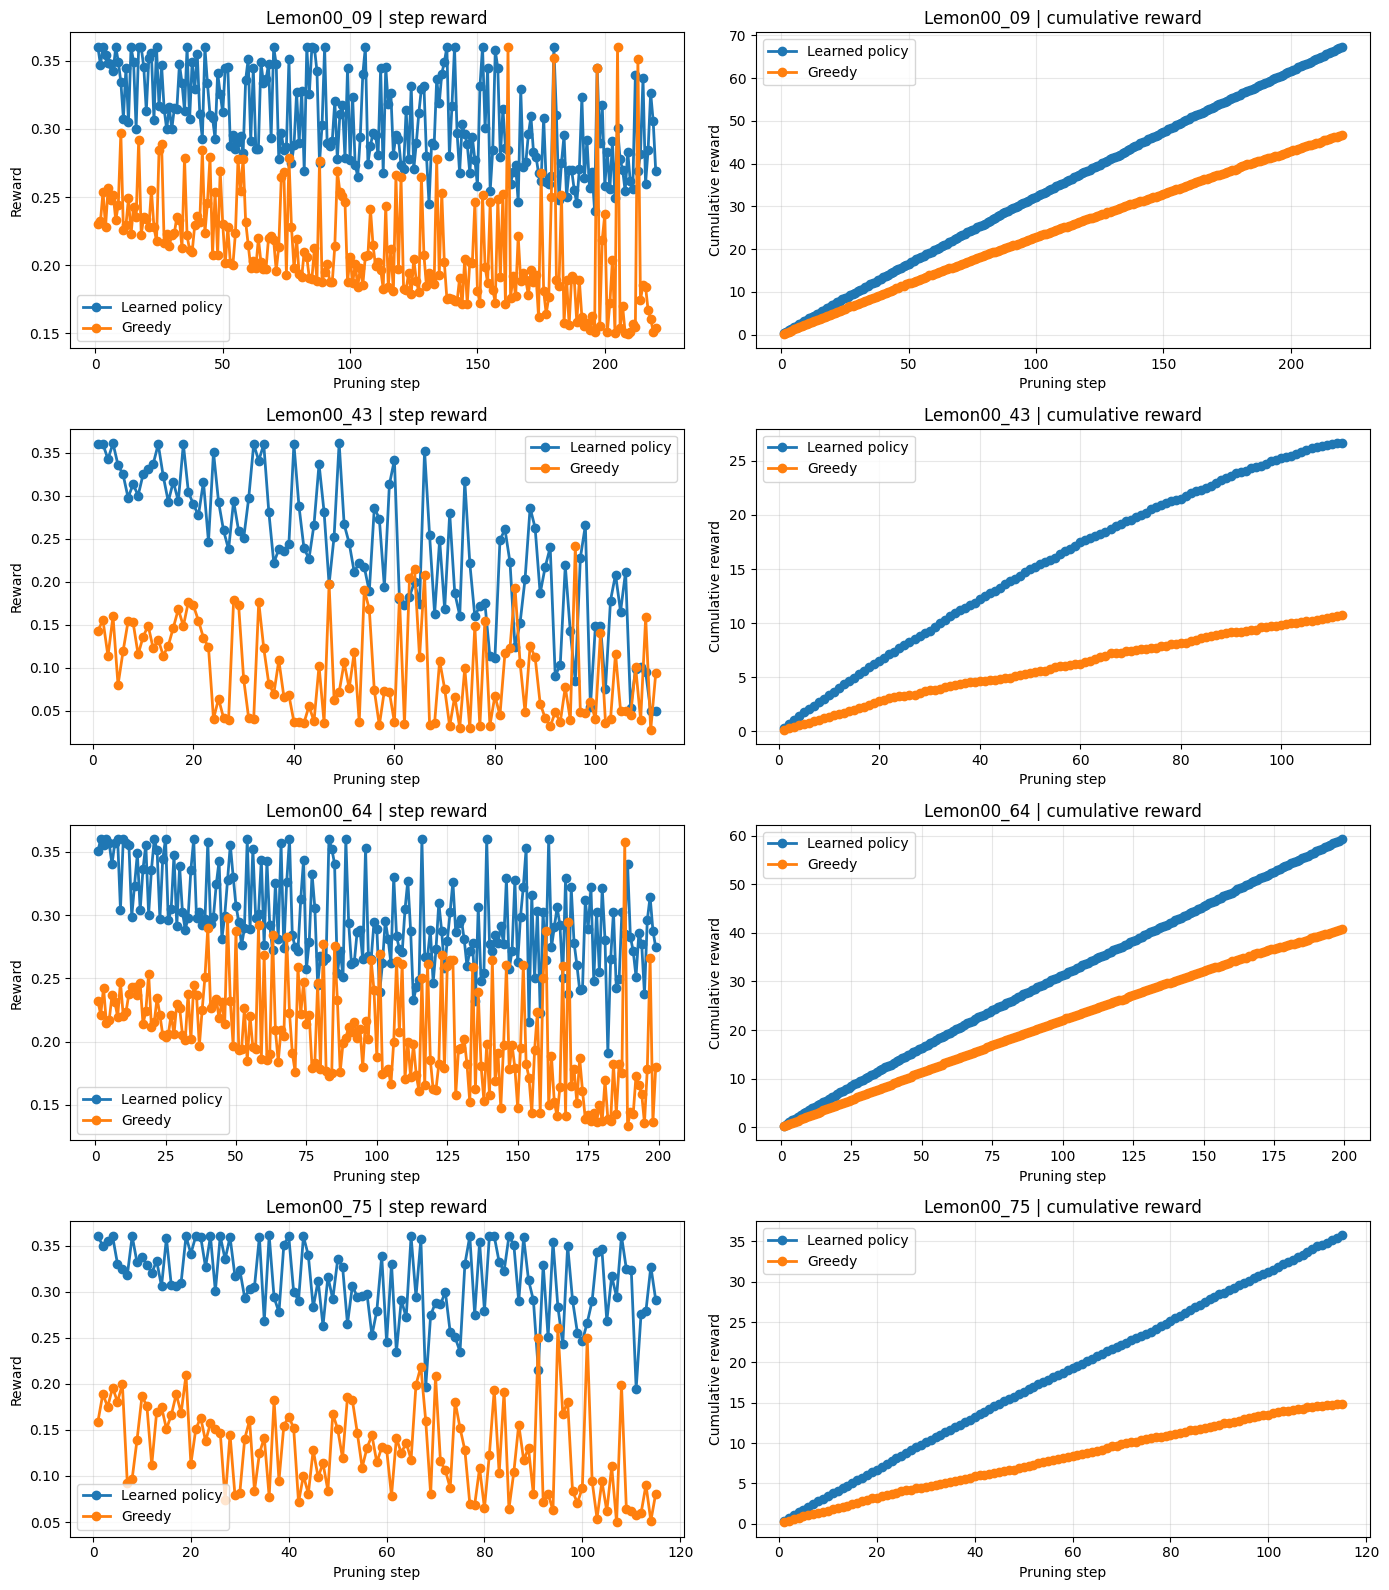

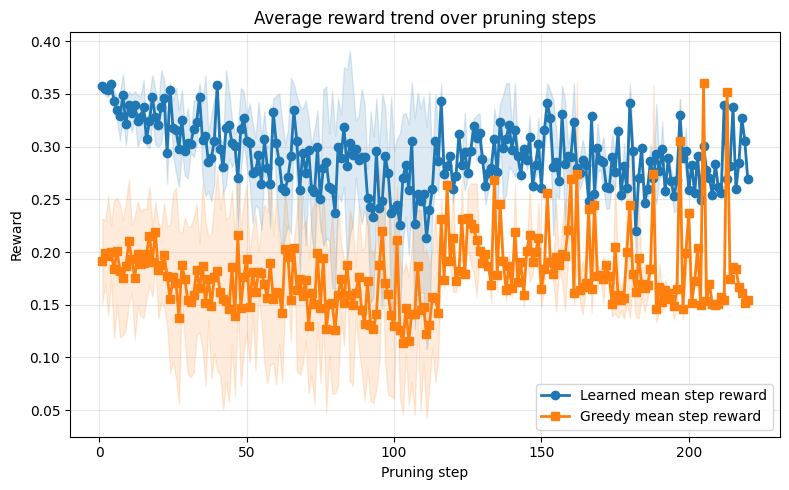

In [6]:
from pathlib import Path
from typing import Any, Dict, List, Tuple

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
from torch_geometric.data import Batch
from gnn_rl_core import GATStateEncoder, GNNSurrogateEnv, convert_to_pyg_data
from generate_trajectories import (
    STOP_ACTION,
    MAX_PRUNING_RATIO,
    _read_point_cloud,
    _read_skeleton,
    _build_graph,
    _branch_to_nodes,
    _root_branch_id,
    _point_branch_ids,
    _remove_branch_state,
    _removed_branch_ids_for_action,
    find_worst_branch,
)
from utils import calculate_step_reward

device = globals().get("device", torch.device("cuda" if torch.cuda.is_available() else "cpu"))
CHECKPOINT_DIR = Path(globals().get("CHECKPOINT_DIR", Path("./checkpoints/graph_gnn")))

class GraphPruningAgent(nn.Module):
    def __init__(self, action_dim: int, state_dim: int = 128, dropout: float = 0.10) -> None:
        super().__init__()
        self.encoder = GATStateEncoder(
            node_in_dim=6,
            hidden_dim=128,
            graph_out_dim=64,
            point_out_dim=64,
            state_dim=state_dim,
            num_gat_layers=3,
            heads=4,
            dropout=dropout,
            pool="meanmax",
        )
        self.policy_head = nn.Sequential(
            nn.LayerNorm(state_dim),
            nn.Linear(state_dim, state_dim),
            nn.ReLU(inplace=True),
            nn.Dropout(dropout),
            nn.Linear(state_dim, action_dim),
        )

        self.surrogate_env = GNNSurrogateEnv(
            action_dim=action_dim,
            state_dim=state_dim,
            action_emb_dim=64,
            hidden_dims=(256, 128),
            output_dim=6,
            dropout=dropout,
        )



    def forward(self, graph_batch: Batch, action_idx: torch.Tensor | None = None):
        state_vec = self.encoder(graph_batch)
        policy_logits = self.policy_head(state_vec)
        chosen_actions = policy_logits.argmax(dim=-1) if action_idx is None else action_idx
        delta_pred = self.surrogate_env(state_vec, chosen_actions)
        return state_vec, policy_logits, delta_pred





class GNNCandidateRanker(nn.Module):

    def __init__(self, candidate_dim: int, state_dim: int = 128, dropout: float = 0.15) -> None:
        super().__init__()
        self.encoder = GATStateEncoder(
            node_in_dim=6,
            hidden_dim=128,
            graph_out_dim=64,
            point_out_dim=64,
            state_dim=state_dim,
            num_gat_layers=3,
            heads=4,
            dropout=dropout,
            pool="meanmax",
        )

        self.scorer = nn.Sequential(
            nn.Linear(state_dim + candidate_dim, 192),
            nn.ReLU(inplace=True),
            nn.Dropout(dropout),
            nn.Linear(192, 96),
            nn.ReLU(inplace=True),
            nn.Dropout(dropout),
            nn.Linear(96, 1),
        )



    def forward(self, graph_batch: Batch, candidate_features: torch.Tensor, candidate_mask: torch.Tensor):

        state_vec = self.encoder(graph_batch)
        k = candidate_features.size(1)
        state_expand = state_vec.unsqueeze(1).expand(-1, k, -1)
        fused = torch.cat([state_expand, candidate_features], dim=-1)
        scores = self.scorer(fused).squeeze(-1)
        scores = scores.masked_fill(~candidate_mask, -1e4)
        return scores




BENCHMARK_NUM_TREES = 4
BENCHMARK_SEED = 42
MAX_BENCHMARK_STEPS = 1000
GREEDY_THRESHOLD = 0.45
STOP_ON_NEGATIVE_REWARD = True
RANK_MAX_CANDIDATES = int(globals().get("RANK_MAX_CANDIDATES", 64))
RANK_FEATURE_DIM = int(globals().get("RANK_FEATURE_DIM", 15))
RANK_DROPOUT = float(globals().get("RANK_DROPOUT", 0.15))
RANK_STOP_LOGIT_MARGIN = float(globals().get("RANK_STOP_LOGIT_MARGIN", 0.15))
RL_CKPT_PATH = CHECKPOINT_DIR / "graph_candidate_ranker_best.pt"





def _choose_pointcloud_file(tree_dir: Path) -> Path:
    for candidate in (
        tree_dir / "pointcloud" / "mergePointClouds.ply",
        tree_dir / "pointcloud" / "branchPointClouds.ply",
        tree_dir / "pointcloud" / "leafPointClouds.ply",
    ):
        if candidate.exists():
            return candidate
    raise FileNotFoundError(f"No point cloud found in {tree_dir / 'pointcloud'}")





def _state_payload(point_cloud: np.ndarray, skeleton_data: np.ndarray, graph, initial_branch_count: int):
    return {
        "point_cloud": np.asarray(point_cloud, dtype=np.float32),
        "skeleton_data": np.asarray(skeleton_data, dtype=np.float32),
        "graph": graph,
        "initial_branch_count": int(max(1, initial_branch_count)),
    }





def _build_rank_candidate_tensor(
    point_cloud: np.ndarray,
    skeleton_step: np.ndarray,
    max_candidates: int = RANK_MAX_CANDIDATES,
    timestep: int = 0,
    max_steps: int = MAX_BENCHMARK_STEPS,
    pruning_ratio: float = 0.0,
) -> Tuple[np.ndarray, np.ndarray, List[int]]:

    pc = np.asarray(point_cloud, dtype=np.float32).reshape(-1, 3)
    sk = np.asarray(skeleton_step, dtype=np.float32).reshape(-1, 6)
    sk = sk[np.isfinite(sk).all(axis=1)] if sk.size else sk

    features = np.zeros((max_candidates + 1, RANK_FEATURE_DIM), dtype=np.float32)
    candidate_mask = np.zeros((max_candidates + 1,), dtype=np.bool_)
    stop_label = max_candidates

    if sk.size == 0:
        features[stop_label, 0] = 1.0
        candidate_mask[stop_label] = True
        return features, candidate_mask, []
    

    branch_ids = np.round(sk[:, 5]).astype(int)
    graph = _build_graph(sk)
    root_branch = _root_branch_id(graph) if graph.number_of_nodes() > 0 else None

    raw_candidates = [
        int(b) for b in np.unique(branch_ids)
        if int(b) >= 0 and (root_branch is None or int(b) != int(root_branch))
    ]

    all_xyz = sk[:, :3]
    if pc.size:
        all_xyz = np.concatenate([pc[:, :3], all_xyz], axis=0)

    bbox_min = all_xyz.min(axis=0)
    bbox_max = all_xyz.max(axis=0)
    bbox_span = np.maximum(bbox_max - bbox_min, 1e-6)
    xy_scale = float(np.linalg.norm(bbox_span[:2]) + 1e-6)
    z_scale = float(bbox_span[2] + 1e-6)
    global_scale = float(np.linalg.norm(bbox_span) + 1e-6)



    if root_branch is not None and np.any(branch_ids == root_branch):
        base = sk[branch_ids == root_branch, :3].mean(axis=0)
    else:
        base = sk[np.argmin(sk[:, 2]), :3]
    candidate_rows: List[Tuple[int, np.ndarray, float]] = []

    n_candidates_norm = np.clip(float(len(raw_candidates)) / float(max_candidates), 0.0, 1.0)
    timestep_norm = np.clip(float(timestep) / max(1.0, float(max_steps)), 0.0, 1.0)
    rtg_norm = float(np.clip(1.0 - float(pruning_ratio), 0.0, 1.0))

    for branch_id in raw_candidates:
        branch_mask = branch_ids == int(branch_id)
        pts = sk[branch_mask, :3]
        radii = np.abs(sk[branch_mask, 3]) if branch_mask.any() else np.zeros((1,), dtype=np.float32)
        if pts.size == 0:
            continue



        centroid = pts.mean(axis=0)
        rel = centroid - base
        radial = float(np.linalg.norm(rel[:2]))
        vec_norm = float(np.linalg.norm(rel) + 1e-6)
        angle_deg = float(np.degrees(np.arccos(np.clip(rel[2] / vec_norm, -1.0, 1.0))))
        length = float(np.linalg.norm(pts.max(axis=0) - pts.min(axis=0)))
        inward_penalty = 1.0 - np.clip(radial / xy_scale, 0.0, 1.0)
        vertical_penalty = float(np.clip((35.0 - angle_deg) / 35.0, 0.0, 1.0))
        length_norm = float(np.clip(length / global_scale, 0.0, 2.0))
        heuristic_badness = 0.45 * inward_penalty + 0.35 * vertical_penalty + 0.20 * min(length_norm, 1.0)



        feat = np.array([
            0.0,
            radial / xy_scale,
            angle_deg / 180.0,
            length / global_scale,
            (centroid[2] - base[2]) / z_scale,
            (pts[:, 2].max() - base[2]) / z_scale,
            (pts[:, 2].min() - base[2]) / z_scale,
            float(radii.mean()) / global_scale,
            min(float(len(pts)) / 20.0, 2.0),
            (centroid[0] - base[0]) / xy_scale,
            (centroid[1] - base[1]) / xy_scale,
            n_candidates_norm,
            timestep_norm,
            rtg_norm,
            heuristic_badness,
        ], dtype=np.float32)

        candidate_rows.append((int(branch_id), feat, float(heuristic_badness)))



    candidate_rows.sort(key=lambda x: x[2], reverse=True)
    selected = candidate_rows[:max_candidates]

    selected_ids: List[int] = []

    for idx, (branch_id, feat, _) in enumerate(selected):
        features[idx] = feat
        candidate_mask[idx] = True
        selected_ids.append(int(branch_id))

    features[stop_label] = np.array([
        1.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0,
        n_candidates_norm, timestep_norm, rtg_norm, 0.0,
    ], dtype=np.float32)
    candidate_mask[stop_label] = True
    return features, candidate_mask, selected_ids


def _load_rl_policy(ckpt_path: Path):
    if not ckpt_path.exists():
        raise FileNotFoundError(f"Policy checkpoint not found: {ckpt_path}")


    checkpoint = torch.load(ckpt_path, map_location=device)
    model_state = checkpoint["model_state"]

    action_values = checkpoint.get("action_values")
    if action_values is not None:
        config = checkpoint.get("config", {})
        state_dim = int(config.get("state_dim", 128))
        dropout = float(config.get("dropout", 0.10))
        model = GraphPruningAgent(action_dim=len(action_values), state_dim=state_dim, dropout=dropout).to(device)
        model.load_state_dict(model_state)
        model.eval()
        return {
            "kind": "global_policy",
            "model": model,
            "action_values": [int(a) for a in action_values],
        }, checkpoint



    scorer_weight = model_state.get("scorer.0.weight")
    inferred_state_dim = int(globals().get("STATE_DIM", 128))

    if scorer_weight is not None:
        inferred_state_dim = int(scorer_weight.shape[1] - RANK_FEATURE_DIM)



    model = GNNCandidateRanker(
        candidate_dim=RANK_FEATURE_DIM,
        state_dim=inferred_state_dim,
        dropout=RANK_DROPOUT,
    ).to(device)
    model.load_state_dict(model_state)
    model.eval()
    return {
        "kind": "candidate_ranker",
        "model": model,
        "action_values": None,
    }, checkpoint





def _select_rl_action(
    policy_bundle,
    point_cloud: np.ndarray,
    skeleton_step: np.ndarray,
    step_idx: int = 0,
    max_steps: int = MAX_BENCHMARK_STEPS,
    pruning_ratio: float = 0.0,
):

    graph = convert_to_pyg_data(skeleton_step, point_cloud)
    graph_batch = Batch.from_data_list([graph]).to(device)


    if policy_bundle["kind"] == "global_policy":
        action_values = policy_bundle["action_values"]
        valid_raw_actions = _build_valid_raw_actions(skeleton_step, stop_action=STOP_ACTION)
        action_to_index = {int(a): i for i, a in enumerate(action_values)}


        with torch.no_grad():
            _, logits, _ = policy_bundle["model"](graph_batch)
            logits = logits[0]
            masked_logits = torch.full_like(logits, -1e4)
            valid_found = False
            for raw_action in valid_raw_actions:
                idx = action_to_index.get(int(raw_action))
                if idx is not None:
                    masked_logits[idx] = logits[idx]
                    valid_found = True


            if not valid_found:
                return STOP_ACTION, {"top_actions": []}
            
            probs = torch.softmax(masked_logits, dim=-1).detach().cpu().numpy()
            topk = min(5, len(probs))
            top_indices = np.argsort(probs)[::-1][:topk]
            debug = [(int(action_values[idx]), float(probs[idx])) for idx in top_indices]
            best_idx = int(masked_logits.argmax(dim=-1).item())
            chosen_raw_action = int(action_values[best_idx])
        return chosen_raw_action, {"top_actions": debug}


    candidate_features, candidate_mask, selected_ids = _build_rank_candidate_tensor(
        point_cloud,
        skeleton_step,
        max_candidates=RANK_MAX_CANDIDATES,
        timestep=step_idx,
        max_steps=max_steps,
        pruning_ratio=pruning_ratio,
    )

    candidate_features_t = torch.from_numpy(candidate_features).unsqueeze(0).float().to(device)
    candidate_mask_t = torch.from_numpy(candidate_mask).unsqueeze(0).bool().to(device)

    with torch.no_grad():
        scores = policy_bundle["model"](graph_batch, candidate_features_t, candidate_mask_t)[0]
        probs = torch.softmax(scores, dim=-1).detach().cpu().numpy()
        topk = min(5, len(probs))
        top_indices = np.argsort(probs)[::-1][:topk]



    debug = []
    for idx in top_indices:

        if int(idx) == RANK_MAX_CANDIDATES:
            debug.append(("STOP", float(probs[idx])))
        elif int(idx) < len(selected_ids):
            debug.append((int(selected_ids[int(idx)]), float(probs[idx])))

    best_idx = int(np.argmax(probs))
    stop_idx = int(RANK_MAX_CANDIDATES)

    if best_idx == stop_idx:
        if len(selected_ids) > 0:
            best_cut_idx = int(np.argmax(probs[: len(selected_ids)]))
            stop_prob = float(probs[stop_idx])
            cut_prob = float(probs[best_cut_idx])
            if (stop_prob - cut_prob) < float(RANK_STOP_LOGIT_MARGIN):
                return int(selected_ids[best_cut_idx]), {
                    "top_actions": debug,
                    "stop_override": True,
                    "stop_prob": stop_prob,
                    "best_cut_prob": cut_prob,
                }
        return STOP_ACTION, {"top_actions": debug}
    if best_idx >= len(selected_ids):
        return STOP_ACTION, {"top_actions": debug}
    return int(selected_ids[best_idx]), {"top_actions": debug}



def rollout_tree(tree_dir: Path, policy_name: str, rl_model=None, rl_action_values=None, max_steps: int = MAX_BENCHMARK_STEPS):
    point_cloud = _read_point_cloud(_choose_pointcloud_file(tree_dir))
    skeleton_data = _read_skeleton(tree_dir / "skeleton" / "skeleton.txt")
    graph = _build_graph(skeleton_data)
    branch_nodes = _branch_to_nodes(graph)
    root_branch = _root_branch_id(graph)
    point_branch_ids = _point_branch_ids(point_cloud, skeleton_data)
    cuttable = [b for b in branch_nodes.keys() if int(b) >= 0 and int(b) != int(root_branch)]
    initial_branch_count = len(set(cuttable))

    if initial_branch_count <= 0:
        return {
            "tree_name": tree_dir.name,
            "policy": policy_name,
            "rewards": [],
            "cumulative_rewards": [],
            "pruning_ratios": [],
            "actions": [],
            "total_reward": 0.0,
            "final_pruning_ratio": 0.0,
            "step_details": [],
        }



    max_allowed_cuts = max(1, int(np.floor(MAX_PRUNING_RATIO * initial_branch_count + 1e-8)))
    pruned_branch_ids = set()

    rewards = []
    cumulative_rewards = []
    pruning_ratios = []
    actions = []
    step_details = []
    cumulative = 0.0



    for step in range(max_steps):
        valid_branches = [b for b in branch_nodes.keys() if int(b) >= 0 and int(b) != int(root_branch)]
        current_ratio = len(pruned_branch_ids) / float(max(1, initial_branch_count))
        if (not valid_branches) or current_ratio >= MAX_PRUNING_RATIO or len(pruned_branch_ids) >= max_allowed_cuts:
            break

        if policy_name == "rl":
            chosen_branch, extra = _select_rl_action(
                rl_model,
                point_cloud,
                skeleton_data,
                step_idx=step,
                max_steps=max_steps,
                pruning_ratio=current_ratio,
            )
            if int(chosen_branch) == STOP_ACTION:
                break

        elif policy_name == "greedy":
            chosen_branch, score = find_worst_branch(graph, branch_nodes, root_branch)
            extra = {"heuristic_score": float(score) if score is not None else float("nan")}
            if chosen_branch is None:
                break
        else:
            raise ValueError(f"Unknown policy_name: {policy_name}")


        removed_branch_id_set = _removed_branch_ids_for_action(graph, int(chosen_branch), branch_nodes)
        if not removed_branch_id_set:
            branch_nodes.pop(int(chosen_branch), None)
            continue

        projected = len(pruned_branch_ids.union(removed_branch_id_set))
        if projected > max_allowed_cuts:
            break

        next_point_cloud, next_skeleton, next_point_branch_ids, _, removed_branches = _remove_branch_state(
            point_cloud,
            skeleton_data,
            point_branch_ids,
            int(chosen_branch),
            graph,
            branch_nodes,
        )

        if removed_branches == 0:
            branch_nodes.pop(int(chosen_branch), None)
            continue

        next_graph = _build_graph(next_skeleton)
        reward = float(
            calculate_step_reward(
                old_state=_state_payload(point_cloud, skeleton_data, graph, initial_branch_count),
                new_state=_state_payload(next_point_cloud, next_skeleton, next_graph, initial_branch_count),
                action_branch=int(chosen_branch),
                is_stop_action=False,
            )
        )
        if STOP_ON_NEGATIVE_REWARD and reward < 0.0:
            break

        pruned_branch_ids.update(removed_branch_id_set)
        cumulative += reward
        rewards.append(reward)
        cumulative_rewards.append(cumulative)
        pruning_ratios.append(len(pruned_branch_ids) / float(max(1, initial_branch_count)))
        actions.append(int(chosen_branch))
        step_details.append(
            {
                "step": step + 1,
                "action": int(chosen_branch),
                "reward": float(reward),
                "cumulative_reward": float(cumulative),
                "pruning_ratio": float(pruning_ratios[-1]),
                **extra,
            }
        )

        point_cloud = next_point_cloud
        skeleton_data = next_skeleton
        point_branch_ids = next_point_branch_ids
        graph = next_graph
        branch_nodes = _branch_to_nodes(graph)
        if graph.number_of_nodes() > 0:
            root_branch = _root_branch_id(graph)

    return {
        "tree_name": tree_dir.name,
        "policy": policy_name,
        "rewards": rewards,
        "cumulative_rewards": cumulative_rewards,
        "pruning_ratios": pruning_ratios,
        "actions": actions,
        "total_reward": float(sum(rewards)),
        "final_pruning_ratio": float(pruning_ratios[-1]) if pruning_ratios else 0.0,
        "step_details": step_details,
    }





raw_tree_dirs = [
    p for p in sorted(Path("./data").iterdir())
    if p.is_dir() and p.name != "trajectories" and (p / "skeleton" / "skeleton.txt").exists() and (p / "pointcloud").exists()

]

if not raw_tree_dirs:
    raise FileNotFoundError("No raw tree folders found under ./data")

rng = np.random.default_rng(BENCHMARK_SEED)
selected_idx = rng.choice(len(raw_tree_dirs), size=min(BENCHMARK_NUM_TREES, len(raw_tree_dirs)), replace=False)
sampled_tree_dirs = [raw_tree_dirs[int(i)] for i in np.sort(selected_idx)]
rl_model, rl_checkpoint = _load_rl_policy(RL_CKPT_PATH)

print(
    f"Loaded learned checkpoint: {RL_CKPT_PATH} | kind={rl_model['kind']} | epoch={rl_checkpoint.get('epoch', 'NA')}"
)
print("Sampled trees:", [p.name for p in sampled_tree_dirs])
benchmark_results = []
summary_rows = []

for tree_dir in sampled_tree_dirs:
    rl_result = rollout_tree(tree_dir, policy_name="rl", rl_model=rl_model)
    greedy_result = rollout_tree(tree_dir, policy_name="greedy")
    benchmark_results.append({"tree": tree_dir.name, "rl": rl_result, "greedy": greedy_result})

    summary_rows.append({
        "tree": tree_dir.name,
        "policy": "Learned",
        "steps": len(rl_result["rewards"]),
        "total_reward": rl_result["total_reward"],
        "final_pruning_ratio": rl_result["final_pruning_ratio"],
        "first_actions": rl_result["actions"][:5],
    })

    summary_rows.append({
        "tree": tree_dir.name,
        "policy": "Greedy",
        "steps": len(greedy_result["rewards"]),
        "total_reward": greedy_result["total_reward"],
        "final_pruning_ratio": greedy_result["final_pruning_ratio"],
        "first_actions": greedy_result["actions"][:5],
    })


for row in summary_rows:
    print(
        f"{row['tree']:>10s} | {row['policy']:<7s} | steps={row['steps']:>2d} | "
        f"total_reward={row['total_reward']:+.4f} | prune_ratio={row['final_pruning_ratio']:.3f} | "
        f"actions={row['first_actions']}"
    )



if benchmark_results:
    fig, axes = plt.subplots(len(benchmark_results), 2, figsize=(14, 4 * len(benchmark_results)), squeeze=False)
    for row_idx, item in enumerate(benchmark_results):
        tree_name = item["tree"]
        for label, color, result in [
            ("Learned policy", "tab:blue", item["rl"]),
            ("Greedy", "tab:orange", item["greedy"]),
        ]:

            x = np.arange(1, len(result["rewards"]) + 1)

            if len(x) == 0:
                continue
            axes[row_idx, 0].plot(x, result["rewards"], marker="o", linewidth=2, label=label, color=color)
            axes[row_idx, 1].plot(x, result["cumulative_rewards"], marker="o", linewidth=2, label=label, color=color)
        axes[row_idx, 0].set_title(f"{tree_name} | step reward")
        axes[row_idx, 0].set_xlabel("Pruning step")
        axes[row_idx, 0].set_ylabel("Reward")
        axes[row_idx, 0].grid(True, alpha=0.3)
        axes[row_idx, 0].legend()

        axes[row_idx, 1].set_title(f"{tree_name} | cumulative reward")
        axes[row_idx, 1].set_xlabel("Pruning step")
        axes[row_idx, 1].set_ylabel("Cumulative reward")
        axes[row_idx, 1].grid(True, alpha=0.3)
        axes[row_idx, 1].legend()
    plt.tight_layout()
    plt.show()


def _aggregate_curve(results, key: str):
    max_len = max((len(r[key]) for r in results), default=0)
    arr = np.full((len(results), max_len), np.nan, dtype=np.float32)
    for i, result in enumerate(results):
        values = np.asarray(result[key], dtype=np.float32)
        arr[i, : len(values)] = values
    return np.nanmean(arr, axis=0), np.nanstd(arr, axis=0)





if benchmark_results:
    rl_rollouts = [item["rl"] for item in benchmark_results]
    greedy_rollouts = [item["greedy"] for item in benchmark_results]
    rl_mean, rl_std = _aggregate_curve(rl_rollouts, "rewards")
    greedy_mean, greedy_std = _aggregate_curve(greedy_rollouts, "rewards")
    plt.figure(figsize=(8, 5))
    x_rl = np.arange(1, len(rl_mean) + 1)
    x_gr = np.arange(1, len(greedy_mean) + 1)
    plt.plot(x_rl, rl_mean, color="tab:blue", linewidth=2, marker="o", label="Learned mean step reward")
    plt.fill_between(x_rl, rl_mean - rl_std, rl_mean + rl_std, color="tab:blue", alpha=0.15)
    plt.plot(x_gr, greedy_mean, color="tab:orange", linewidth=2, marker="s", label="Greedy mean step reward")
    plt.fill_between(x_gr, greedy_mean - greedy_std, greedy_mean + greedy_std, color="tab:orange", alpha=0.15)
    plt.title("Average reward trend over pruning steps")
    plt.xlabel("Pruning step")
    plt.ylabel("Reward")
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.show()



/tmp/ipykernel_369019/3869790714.py:80: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = plt.cm.get_cmap("tab20", max(1, len(unique_branch_ids)))


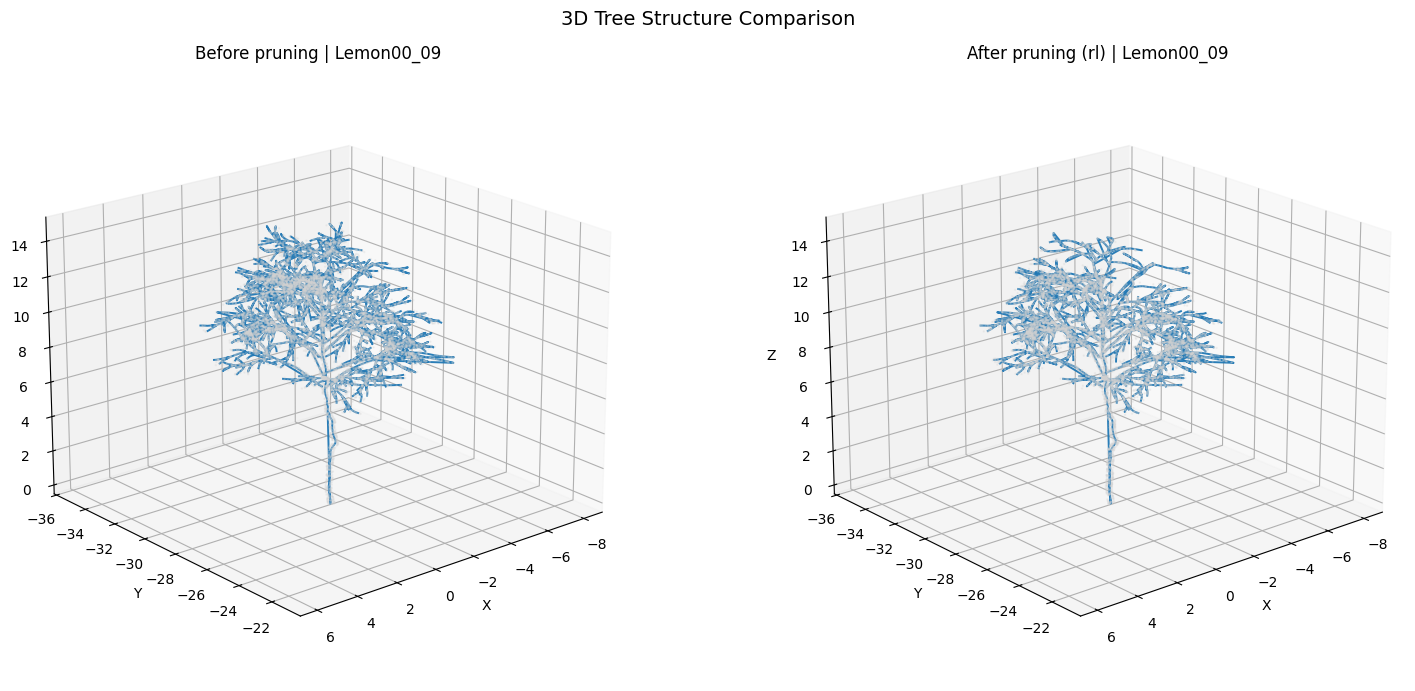

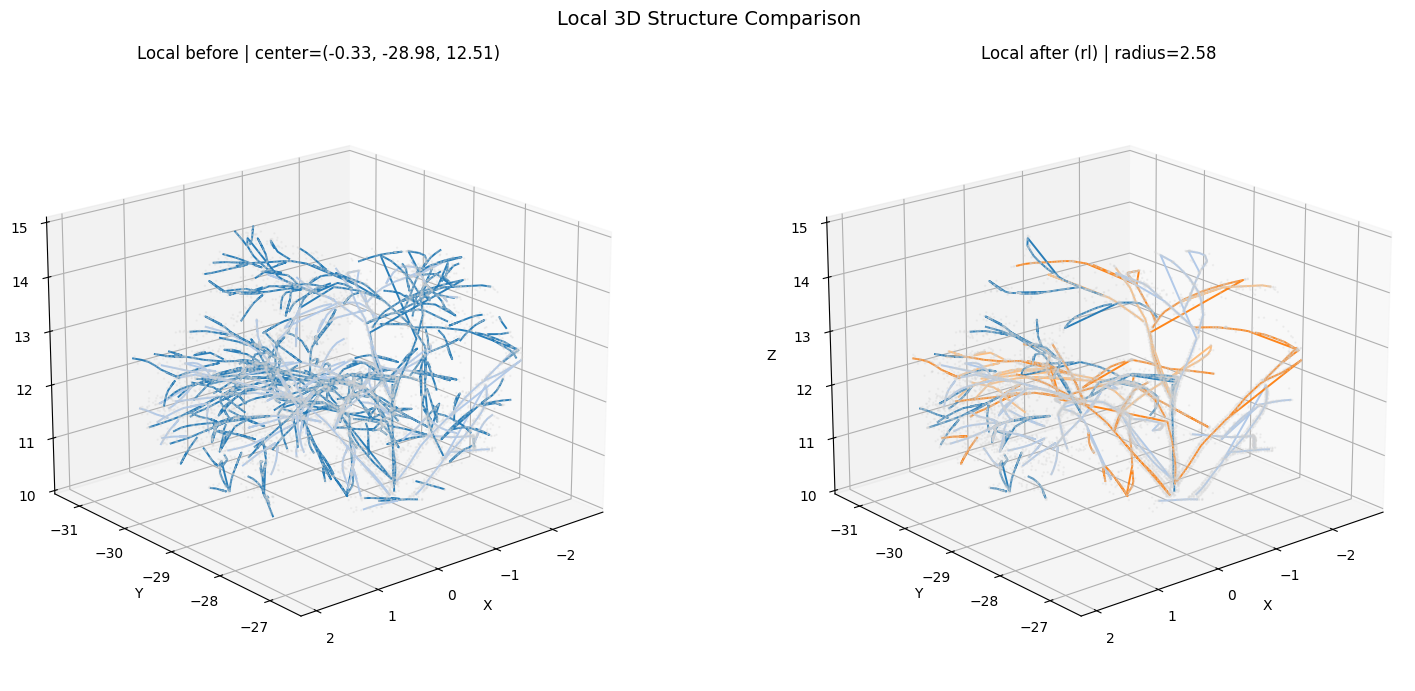

Tree=Lemon00_09 | policy=rl | planned_actions=220 | applied_actions=220 | skeleton_nodes_before=7111 | skeleton_nodes_after=5538
Local focus center=(-0.333, -28.979, 12.514) | local_radius=2.580


In [7]:
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401 (needed for 3D projection)

def _apply_action_sequence(tree_dir: Path, actions):
    point_cloud = _read_point_cloud(_choose_pointcloud_file(tree_dir))
    skeleton_data = _read_skeleton(tree_dir / "skeleton" / "skeleton.txt")
    graph = _build_graph(skeleton_data)
    point_branch_ids = _point_branch_ids(point_cloud, skeleton_data)

    init_pc = np.asarray(point_cloud, dtype=np.float32).copy()
    init_sk = np.asarray(skeleton_data, dtype=np.float32).copy()

    applied_actions = []
    for action in actions:
        branch_nodes = _branch_to_nodes(graph)
        if graph.number_of_nodes() == 0:
            break
        root_branch = _root_branch_id(graph)
        valid_branches = {int(b) for b in branch_nodes.keys() if int(b) >= 0 and int(b) != int(root_branch)}
        action = int(action)
        if action not in valid_branches:
            continue

        removed_branch_id_set = _removed_branch_ids_for_action(graph, action, branch_nodes)
        if not removed_branch_id_set:
            continue

        next_point_cloud, next_skeleton, next_point_branch_ids, _, removed_branches = _remove_branch_state(
            point_cloud,
            skeleton_data,
            point_branch_ids,
            action,
            graph,
            branch_nodes,
        )
        if removed_branches <= 0:
            continue

        point_cloud = next_point_cloud
        skeleton_data = next_skeleton
        point_branch_ids = next_point_branch_ids
        graph = _build_graph(skeleton_data)
        applied_actions.append(action)

    return init_pc, init_sk, np.asarray(point_cloud, dtype=np.float32), np.asarray(skeleton_data, dtype=np.float32), applied_actions


def _plot_tree_3d(
    ax,
    point_cloud: np.ndarray,
    skeleton_data: np.ndarray,
    title: str,
    local_center: np.ndarray | None = None,
    local_radius: float | None = None,
):
    pc = np.asarray(point_cloud, dtype=np.float32).reshape(-1, 3) if point_cloud is not None else np.zeros((0, 3), dtype=np.float32)
    sk = np.asarray(skeleton_data, dtype=np.float32).reshape(-1, 6) if skeleton_data is not None else np.zeros((0, 6), dtype=np.float32)
    sk = sk[np.isfinite(sk).all(axis=1)] if sk.size else sk

    if local_center is not None and local_radius is not None and local_radius > 0:
        center = np.asarray(local_center, dtype=np.float32).reshape(1, 3)
        if pc.size:
            pc_mask = np.linalg.norm(pc[:, :3] - center, axis=1) <= float(local_radius)
            pc = pc[pc_mask]
        if sk.size:
            sk_mask = np.linalg.norm(sk[:, :3] - center, axis=1) <= float(local_radius)
            sk = sk[sk_mask]

    if pc.size:
        max_points = 12000
        if len(pc) > max_points:
            idx = np.random.default_rng(42).choice(len(pc), size=max_points, replace=False)
            pc_show = pc[idx]
        else:
            pc_show = pc
        ax.scatter(pc_show[:, 0], pc_show[:, 1], pc_show[:, 2], s=0.5, c="lightgray", alpha=0.25)

    if sk.size:
        branch_ids = np.round(sk[:, 5]).astype(int)
        unique_branch_ids = np.unique(branch_ids)
        cmap = plt.cm.get_cmap("tab20", max(1, len(unique_branch_ids)))
        for i, branch_id in enumerate(unique_branch_ids):
            pts = sk[branch_ids == branch_id, :3]
            if len(pts) == 0:
                continue
            color = cmap(i % 20)
            ax.plot(pts[:, 0], pts[:, 1], pts[:, 2], color=color, linewidth=1.4, alpha=0.95)

    ax.set_title(title)
    ax.set_xlabel("X")
    ax.set_ylabel("Y")
    ax.set_zlabel("Z")


def _set_equal_limits(ax_left, ax_right, before_pc, before_sk, after_pc, after_sk):
    clouds = []
    for arr in (before_pc, after_pc):
        arr = np.asarray(arr, dtype=np.float32).reshape(-1, 3) if arr is not None else np.zeros((0, 3), dtype=np.float32)
        if arr.size:
            clouds.append(arr[:, :3])
    for arr in (before_sk, after_sk):
        arr = np.asarray(arr, dtype=np.float32).reshape(-1, 6) if arr is not None else np.zeros((0, 6), dtype=np.float32)
        if arr.size:
            clouds.append(arr[:, :3])

    if not clouds:
        return

    all_xyz = np.concatenate(clouds, axis=0)
    xyz_min = all_xyz.min(axis=0)
    xyz_max = all_xyz.max(axis=0)
    center = (xyz_min + xyz_max) / 2.0
    span = float(np.max(xyz_max - xyz_min))
    half = max(span / 2.0, 1e-3)

    for ax in (ax_left, ax_right):
        ax.set_xlim(center[0] - half, center[0] + half)
        ax.set_ylim(center[1] - half, center[1] + half)
        ax.set_zlim(center[2] - half, center[2] + half)
        ax.view_init(elev=20, azim=50)


def _infer_local_focus(before_sk: np.ndarray, action_seq: list[int]):
    sk = np.asarray(before_sk, dtype=np.float32).reshape(-1, 6) if before_sk is not None else np.zeros((0, 6), dtype=np.float32)
    sk = sk[np.isfinite(sk).all(axis=1)] if sk.size else sk
    if sk.size == 0:
        return np.zeros((3,), dtype=np.float32), 1.0

    branch_ids = np.round(sk[:, 5]).astype(int)
    focus_center = None
    for action in action_seq:
        mask = branch_ids == int(action)
        if mask.any():
            focus_center = sk[mask, :3].mean(axis=0)
            break
    if focus_center is None:
        focus_center = sk[:, :3].mean(axis=0)

    bbox_span = np.maximum(sk[:, :3].max(axis=0) - sk[:, :3].min(axis=0), 1e-6)
    diag = float(np.linalg.norm(bbox_span))
    local_radius = max(0.12 * diag, 0.8)
    return focus_center.astype(np.float32), float(local_radius)


if not benchmark_results:
    raise RuntimeError("benchmark_results is empty. Please run the benchmark cell first.")

compare_tree_name = benchmark_results[0]["tree"]
compare_policy_key = "rl"  # choose from: "rl" or "greedy"
compare_actions = benchmark_results[0][compare_policy_key]["actions"]

tree_dir_map = {p.name: p for p in raw_tree_dirs}
if compare_tree_name not in tree_dir_map:
    raise FileNotFoundError(f"Tree {compare_tree_name} not found in raw_tree_dirs.")

tree_dir = tree_dir_map[compare_tree_name]
before_pc, before_sk, after_pc, after_sk, applied_actions = _apply_action_sequence(tree_dir, compare_actions)

# Global structure comparison
fig = plt.figure(figsize=(16, 7))
ax1 = fig.add_subplot(1, 2, 1, projection="3d")
ax2 = fig.add_subplot(1, 2, 2, projection="3d")

_plot_tree_3d(ax1, before_pc, before_sk, f"Before pruning | {compare_tree_name}")
_plot_tree_3d(ax2, after_pc, after_sk, f"After pruning ({compare_policy_key}) | {compare_tree_name}")
_set_equal_limits(ax1, ax2, before_pc, before_sk, after_pc, after_sk)

fig.suptitle("3D Tree Structure Comparison", fontsize=14)
plt.tight_layout()
plt.show()

# Local patch comparison around first actionable pruned branch
local_center, local_radius = _infer_local_focus(before_sk, applied_actions if len(applied_actions) > 0 else compare_actions)
fig_local = plt.figure(figsize=(16, 7))
axl1 = fig_local.add_subplot(1, 2, 1, projection="3d")
axl2 = fig_local.add_subplot(1, 2, 2, projection="3d")

_plot_tree_3d(
    axl1, before_pc, before_sk,
    f"Local before | center=({local_center[0]:.2f}, {local_center[1]:.2f}, {local_center[2]:.2f})",
    local_center=local_center,
    local_radius=local_radius,
 )
_plot_tree_3d(
    axl2, after_pc, after_sk,
    f"Local after ({compare_policy_key}) | radius={local_radius:.2f}",
    local_center=local_center,
    local_radius=local_radius,
 )
_set_equal_limits(axl1, axl2, before_pc, before_sk, after_pc, after_sk)

# Tighten local view limits to the selected patch for better visual contrast
for ax in (axl1, axl2):
    ax.set_xlim(local_center[0] - local_radius, local_center[0] + local_radius)
    ax.set_ylim(local_center[1] - local_radius, local_center[1] + local_radius)
    ax.set_zlim(local_center[2] - local_radius, local_center[2] + local_radius)
    ax.view_init(elev=20, azim=50)

fig_local.suptitle("Local 3D Structure Comparison", fontsize=14)
plt.tight_layout()
plt.show()

print(
    f"Tree={compare_tree_name} | policy={compare_policy_key} | "
    f"planned_actions={len(compare_actions)} | applied_actions={len(applied_actions)} | "
    f"skeleton_nodes_before={len(before_sk)} | skeleton_nodes_after={len(after_sk)}"
 )
print(
    f"Local focus center=({local_center[0]:.3f}, {local_center[1]:.3f}, {local_center[2]:.3f}) | "
    f"local_radius={local_radius:.3f}"
 )